# AtliQ Grands: KPI Validation and Analysis

This notebook rebuilds the Power BI model in Python to **independently check every dashboard KPI** and to dig into the questions behind the findings in the README.

**Steps**
1. Load the five raw tables
2. Rebuild the date table the same way Power BI does
3. Check data quality
4. Recalculate the dashboard KPIs
5. Break the KPIs down by city, room class, day type, platform and hotel
6. Check the week-over-week calculations

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RAW = '../data/raw/'

fact_bookings = pd.read_csv(RAW + 'fact_bookings.csv', parse_dates=['booking_date', 'check_in_date', 'checkout_date'])
fact_agg = pd.read_csv(RAW + 'fact_aggregated_bookings.csv')
fact_agg['check_in_date'] = pd.to_datetime(fact_agg['check_in_date'], format='%d-%b-%Y')
dim_date = pd.read_csv(RAW + 'dim_date.csv')
dim_hotels = pd.read_csv(RAW + 'dim_hotels.csv')
dim_rooms = pd.read_csv(RAW + 'dim_rooms.csv')

for name, df in [('fact_bookings', fact_bookings), ('fact_aggregated_bookings', fact_agg),
                 ('dim_date', dim_date), ('dim_hotels', dim_hotels), ('dim_rooms', dim_rooms)]:
    print(f'{name:26} {df.shape[0]:>7,} rows  {df.shape[1]} columns')

fact_bookings              134,590 rows  12 columns
fact_aggregated_bookings     9,200 rows  5 columns
dim_date                        92 rows  4 columns
dim_hotels                      25 rows  4 columns
dim_rooms                        4 rows  2 columns


## 2. Rebuild the date table

The same changes made in Power BI:
- **`day_type`**: the raw column treats Saturday and Sunday as the weekend. In hotels the busy weekend nights are **Friday and Saturday**, so it is rebuilt.
- **`wn`**: the raw `week no` column stores text like `W 19`. It is replaced with a number so weeks can be sorted and compared. This matches DAX `WEEKNUM(date)`, where weeks start on Sunday.

In [2]:
dim_date['date'] = pd.to_datetime(dim_date['date'], format='mixed')
print('Raw day_type for Sunday 1 May 2022:', dim_date.loc[0, 'day_type'])

dim_date['day_type'] = np.where(dim_date['date'].dt.day_of_week.isin([4, 5]), 'Weekend', 'Weekday')  # 4 = Friday, 5 = Saturday
dim_date['wn'] = dim_date['date'].dt.strftime('%U').astype(int) + 1
dim_date['month'] = dim_date['date'].dt.strftime('%b')

assert (dim_date['week no'].str.replace('W ', '').astype(int) == dim_date['wn']).all()
dim_date = dim_date.drop(columns=['week no'])

print(dim_date['day_type'].value_counts().to_dict())
print('Days in each week:', dim_date.groupby('wn').size().to_dict())

Raw day_type for Sunday 1 May 2022: weekend
{'Weekday': 66, 'Weekend': 26}
Days in each week: {19: 7, 20: 7, 21: 7, 22: 7, 23: 7, 24: 7, 25: 7, 26: 7, 27: 7, 28: 7, 29: 7, 30: 7, 31: 7, 32: 1}


26 weekend days is exactly 13 Fridays and 13 Saturdays. Week 32 has only **one day** (Sunday 31 July). It is filtered out in section 4, as in the dashboard.

## 3. Data quality checks

In [3]:
checks = {
    'Duplicate booking IDs': fact_bookings['booking_id'].duplicated().sum(),
    'Checkout on or before check-in': (fact_bookings['checkout_date'] <= fact_bookings['check_in_date']).sum(),
    'Booked after check-in': (fact_bookings['booking_date'] > fact_bookings['check_in_date']).sum(),
    'Successful bookings above capacity': (fact_agg['successful_bookings'] > fact_agg['capacity']).sum(),
    'Bookings with no matching date': (~fact_bookings['check_in_date'].isin(dim_date['date'])).sum(),
    'Bookings with no matching hotel': (~fact_bookings['property_id'].isin(dim_hotels['property_id'])).sum(),
}
pd.Series(checks, name='rows')

Duplicate booking IDs                 0
Checkout on or before check-in        0
Booked after check-in                 0
Successful bookings above capacity    0
Bookings with no matching date        0
Bookings with no matching hotel       0
Name: rows, dtype: int64

In [4]:
cancelled = fact_bookings[fact_bookings['booking_status'] == 'Cancelled']
print('Share of revenue kept on cancelled bookings:', (cancelled['revenue_realized'] / cancelled['revenue_generated']).round(2).unique())
print('Ratings given by status:', fact_bookings.dropna(subset=['ratings_given'])['booking_status'].value_counts().to_dict())
print('Missing ratings:', fact_bookings['ratings_given'].isna().sum())

Share of revenue kept on cancelled bookings: [0.4]
Ratings given by status: {'Checked Out': 56683}
Missing ratings: 77907


The data is clean. Two things to know:
- Cancelled bookings keep **40%** of their revenue as a cancellation fee.
- Only checked-out guests can leave a rating, so missing ratings are expected, not errors.

In [5]:
# Does successful_bookings include cancelled bookings?
per_slot = fact_bookings.groupby(['property_id', 'check_in_date', 'room_category']).size().rename('all_bookings').reset_index()
check = fact_agg.merge(per_slot, on=['property_id', 'check_in_date', 'room_category'])
print('successful_bookings equals ALL bookings (including cancelled):', (check['successful_bookings'] == check['all_bookings']).all())

successful_bookings equals ALL bookings (including cancelled): True


So **Occupancy %** counts cancelled bookings as occupied rooms. This is how the challenge defines it, but it overstates how full the hotels really were.

## 4. Recalculate the dashboard KPIs

The dashboard has a report-level filter that removes **week 32** (Sunday 31 July, the only day in that week), so it covers 13 complete weeks. The same filter is applied here so the numbers match. Each formula follows the matching DAX measure in the Power BI model.

In [6]:
dim_date_all = dim_date.copy()
dim_date = dim_date[dim_date['wn'] != 32]
print('Days in the analysis:', len(dim_date), f"({dim_date['date'].min():%d %b} to {dim_date['date'].max():%d %b %Y})")

Days in the analysis: 91 (01 May to 30 Jul 2022)


In [7]:
def add_dims(df):
    return (df.merge(dim_date[['date', 'wn', 'day_type', 'month']], left_on='check_in_date', right_on='date')
              .merge(dim_hotels, on='property_id')
              .merge(dim_rooms, left_on='room_category', right_on='room_id'))

bookings = add_dims(fact_bookings)
agg = add_dims(fact_agg)

def kpis(b, a, days):
    n = len(b)
    revenue = b['revenue_realized'].sum()
    capacity = a['capacity'].sum()
    cancelled = (b['booking_status'] == 'Cancelled').sum()
    no_show = (b['booking_status'] == 'No Show').sum()
    checked_out = (b['booking_status'] == 'Checked Out').sum()
    return pd.Series({
        'Revenue': revenue,
        'Total Bookings': n,
        'Total Capacity': capacity,
        'Occupancy %': a['successful_bookings'].sum() / capacity,
        'Average Rating': b['ratings_given'].mean(),
        'Cancellation %': cancelled / n,
        'No Show rate %': no_show / n,
        'Realisation %': 1 - (cancelled + no_show) / n,
        'ADR': revenue / n,
        'RevPAR': revenue / capacity,
        'DBRN': n / days,
        'DSRN': capacity / days,
        'DURN': checked_out / days,
    })

overall = kpis(bookings, agg, days=len(dim_date))
overall.apply(lambda v: f'{v:,.4f}' if v < 10 else f'{v:,.0f}')

Revenue           1,687,760,868
Total Bookings          132,939
Total Capacity          230,048
Occupancy %              0.5779
Average Rating           3.6190
Cancellation %           0.2484
No Show rate %           0.0502
Realisation %            0.7014
ADR                      12,696
RevPAR                    7,337
DBRN                      1,461
DSRN                      2,528
DURN                      1,025
dtype: str

In [8]:
lost = bookings['revenue_generated'].sum() - bookings['revenue_realized'].sum()
print(f'Revenue booked:   ₹{bookings["revenue_generated"].sum():,}')
print(f'Revenue realized: ₹{bookings["revenue_realized"].sum():,}')
print(f'Lost to cancellations: ₹{lost:,} ({lost / bookings["revenue_generated"].sum():.1%} of booked revenue)')

Revenue booked:   ₹1,982,994,975
Revenue realized: ₹1,687,760,868
Lost to cancellations: ₹295,234,107 (14.9% of booked revenue)


## 5. Breakdowns

In [9]:
def breakdown(col):
    rows = {}
    for key in sorted(bookings[col].unique()):
        days = (dim_date[col] == key).sum() if col in dim_date.columns else len(dim_date)
        rows[key] = kpis(bookings[bookings[col] == key], agg[agg[col] == key], days)
    return pd.DataFrame(rows).T[['Revenue', 'Total Bookings', 'Occupancy %', 'ADR', 'RevPAR', 'Realisation %', 'Average Rating']]

fmt = {'Revenue': '₹{:,.0f}', 'Total Bookings': '{:,.0f}', 'Occupancy %': '{:.1%}', 'ADR': '₹{:,.0f}',
       'RevPAR': '₹{:,.0f}', 'Realisation %': '{:.1%}', 'Average Rating': '{:.2f}'}

### By city

In [10]:
breakdown('city').sort_values('Revenue', ascending=False).style.format(fmt)

,Revenue,Total Bookings,Occupancy %,ADR,RevPAR,Realisation %,Average Rating
Mumbai,"₹660,641,658","42,941",57.8%,"₹15,385","₹8,897",70.2%,3.65
Bangalore,"₹415,030,530","31,617",55.7%,"₹13,127","₹7,309",69.9%,3.41
Hyderabad,"₹321,166,370","34,454",58.0%,"₹9,322","₹5,405",70.3%,3.66
Delhi,"₹290,922,310","23,927",60.4%,"₹12,159","₹7,349",70.1%,3.78


### By room class

In [11]:
breakdown('room_class').sort_values('ADR', ascending=False).style.format(fmt)

,Revenue,Total Bookings,Occupancy %,ADR,RevPAR,Realisation %,Average Rating
Presidential,"₹372,017,834","15,876",59.1%,"₹23,433","₹13,858",70.5%,3.69
Premium,"₹456,361,608","30,186",57.5%,"₹15,118","₹8,691",70.2%,3.59
Elite,"₹553,737,204","48,916",57.6%,"₹11,320","₹6,515",70.0%,3.60
Standard,"₹305,644,222","37,961",57.8%,"₹8,052","₹4,652",70.1%,3.63


### Weekday vs. weekend

In [12]:
breakdown('day_type').style.format(fmt)

,Revenue,Total Bookings,Occupancy %,ADR,RevPAR,Realisation %,Average Rating
Weekday,"₹1,163,801,695","91,765",55.8%,"₹12,682","₹7,083",69.9%,3.62
Weekend,"₹523,959,173","41,174",62.6%,"₹12,725","₹7,972",70.6%,3.62


### By month

In [13]:
breakdown('month').loc[['May', 'Jun', 'Jul']].style.format(fmt)

,Revenue,Total Bookings,Occupancy %,ADR,RevPAR,Realisation %,Average Rating
May,"₹581,930,666","45,882",58.5%,"₹12,683","₹7,426",69.8%,3.63
Jun,"₹553,932,355","43,683",57.6%,"₹12,681","₹7,304",70.1%,3.62
Jul,"₹551,897,847","43,374",57.2%,"₹12,724","₹7,277",70.6%,3.62


### By booking platform

Capacity is not split by platform, so occupancy and RevPAR do not apply here.

In [14]:
platform = bookings.groupby('booking_platform').agg(
    bookings=('booking_id', 'size'),
    revenue=('revenue_realized', 'sum'),
    cancelled=('booking_status', lambda s: (s == 'Cancelled').mean()),
    realisation=('booking_status', lambda s: (s == 'Checked Out').mean()),
)
platform['share'] = platform['bookings'] / platform['bookings'].sum()
platform['ADR'] = platform['revenue'] / platform['bookings']
platform.sort_values('share', ascending=False)[['share', 'bookings', 'cancelled', 'realisation', 'ADR']].style.format(
    {'share': '{:.1%}', 'bookings': '{:,}', 'cancelled': '{:.1%}', 'realisation': '{:.1%}', 'ADR': '₹{:,.0f}'})

,share,bookings,cancelled,realisation,ADR
booking_platform,,,,,
others,40.9%,"54,355",24.9%,70.1%,"₹12,702"
makeyourtrip,20.0%,"26,614",25.0%,69.9%,"₹12,665"
logtrip,11.0%,"14,594",24.4%,70.6%,"₹12,705"
direct online,9.9%,"13,191",25.0%,70.3%,"₹12,638"
tripster,7.1%,"9,503",25.0%,69.8%,"₹12,778"
journey,6.0%,"8,011",24.8%,70.5%,"₹12,656"
direct offline,5.0%,"6,671",24.5%,70.2%,"₹12,794"


### By hotel

Two hotels share the name *Atliq Exotica, Mumbai*, so hotels are identified by `property_id`.

In [15]:
hotel = pd.DataFrame({pid: kpis(bookings[bookings['property_id'] == pid], agg[agg['property_id'] == pid], len(dim_date))
                      for pid in dim_hotels['property_id']}).T
hotel = dim_hotels.set_index('property_id').join(hotel)
hotel['rating_tier'] = pd.cut(hotel['Average Rating'], [0, 2.6, 3.5, 5], labels=['Low', 'Mid', 'High'])
hotel.sort_values('Average Rating')[['property_name', 'city', 'Average Rating', 'Occupancy %', 'ADR', 'Revenue']].style.format(fmt)

,property_name,city,Average Rating,Occupancy %,ADR,Revenue
property_id,,,,,,
17564,Atliq Seasons,Mumbai,2.30,44.6%,"₹16,597","₹65,294,229"
18559,Atliq Exotica,Hyderabad,2.33,44.6%,"₹9,111","₹47,306,410"
17562,Atliq Bay,Mumbai,2.37,44.9%,"₹15,167","₹51,384,880"
19558,Atliq Grands,Bangalore,2.37,44.3%,"₹12,468","₹53,812,500"
16560,Atliq City,Delhi,3.01,53.6%,"₹11,714","₹54,296,298"
19563,Atliq Palace,Bangalore,3.02,53.4%,"₹12,670","₹67,748,625"
17560,Atliq City,Mumbai,3.04,53.1%,"₹14,629","₹86,894,072"
19559,Atliq Exotica,Bangalore,3.04,53.7%,"₹12,751","₹59,229,150"
17558,Atliq Grands,Mumbai,3.05,53.6%,"₹14,839","₹73,822,772"


### Ratings and occupancy

In [16]:
print('Correlation between rating and occupancy:', round(hotel['Average Rating'].corr(hotel['Occupancy %']), 3))

tiers = hotel.groupby('rating_tier', observed=True).agg(
    hotels=('property_name', 'size'),
    rating=('Average Rating', 'mean'),
    occupancy=('Occupancy %', 'mean'),
    adr=('ADR', 'mean'),
    revenue=('Revenue', 'sum'),
)
tiers.style.format({'rating': '{:.2f}', 'occupancy': '{:.1%}', 'adr': '₹{:,.0f}', 'revenue': '₹{:,.0f}'})

Correlation between rating and occupancy: 0.998


,hotels,rating,occupancy,adr,revenue
rating_tier,,,,,
Low,4,2.34,44.6%,"₹13,336","₹217,798,019"
Mid,9,3.05,53.4%,"₹12,316","₹559,805,771"
High,12,4.28,65.9%,"₹12,827","₹910,157,078"


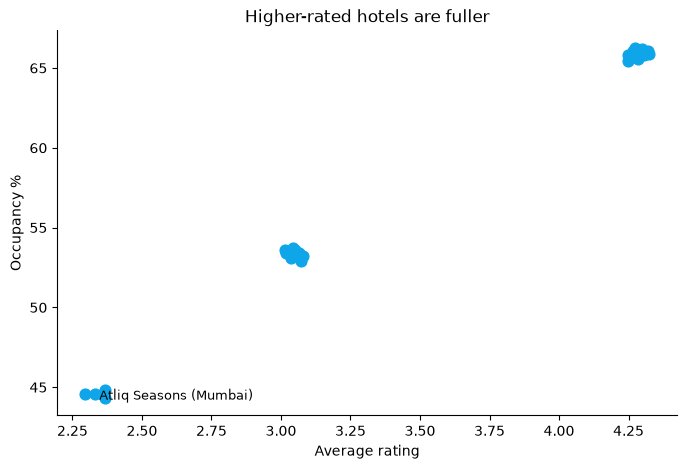

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(hotel['Average Rating'], hotel['Occupancy %'] * 100, s=60, color='#0EA5E9')
low = hotel.sort_values('Average Rating').iloc[0]
ax.annotate(f"{low['property_name']} ({low['city']})", (low['Average Rating'], low['Occupancy %'] * 100),
            textcoords='offset points', xytext=(10, -4), fontsize=9)
ax.set_xlabel('Average rating')
ax.set_ylabel('Occupancy %')
ax.set_title('Higher-rated hotels are fuller')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

Hotels fall into three clear groups, and occupancy rises with each step up in rating. Low-rated hotels charge about the same as high-rated ones, so price is not what keeps them empty.

## 6. Week-over-week check

The dashboard cards compare the selected week with the week before it. When no week is selected, the measures use the **highest week number**. Before week 32 was filtered out, that meant comparing 1 day against 7. This uses all the data, including week 32, to show the difference.

In [18]:
all_weeks = fact_bookings.merge(dim_date_all[['date', 'wn']], left_on='check_in_date', right_on='date')
weekly_revenue = all_weeks.groupby('wn')['revenue_realized'].sum()
print(f"Week 32 vs week 31 (what the card shows by default): {weekly_revenue[32] / weekly_revenue[31] - 1:+.1%}")
print(f"Week 31 vs week 30 (last two complete weeks):        {weekly_revenue[31] / weekly_revenue[30] - 1:+.1%}")

Week 32 vs week 31 (what the card shows by default): -81.7%
Week 31 vs week 30 (last two complete weeks):        +0.2%


The default comparison showed a drop of about 82% that never happened. With week 32 filtered out, the latest week is week 31 and the cards show the real change. Weekly figures for the 13 complete weeks:

In [19]:
weekly = pd.DataFrame({w: kpis(bookings[bookings['wn'] == w], agg[agg['wn'] == w], (dim_date['wn'] == w).sum())
                       for w in sorted(bookings['wn'].unique())}).T
weekly[['Revenue', 'Occupancy %', 'ADR', 'Realisation %']].style.format(fmt)

,Revenue,Occupancy %,ADR,Realisation %
19,"₹138,182,064",62.0%,"₹12,602",69.6%
20,"₹139,435,920",61.9%,"₹12,725",70.3%
21,"₹114,922,175",51.1%,"₹12,710",70.0%
22,"₹138,720,126",61.8%,"₹12,687",69.4%
23,"₹115,568,569",51.4%,"₹12,715",70.4%
24,"₹139,581,703",62.4%,"₹12,642",69.6%
25,"₹138,674,279",61.8%,"₹12,672",70.0%
26,"₹114,152,421",51.0%,"₹12,660",69.8%
27,"₹139,555,632",61.9%,"₹12,731",70.6%
28,"₹139,383,916",61.8%,"₹12,754",71.0%
